In [ ]:
# ==============================================================================
# PHASE 1: DATASET UNDERSTANDING & DATA PREPROCESSING (COLAB READY)
# ==============================================================================

import pandas as pd
import numpy as np
import io
from google.colab import files

# ------------------------------------------------------------------------------
# STEP 0: FILE UPLOAD
# ------------------------------------------------------------------------------
print("Please upload your 'export.csv' file below:")
uploaded = files.upload()

# Read the uploaded CSV
filename = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[filename]))
print(f"\nDataset Successfully Loaded! Initial Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")

# ------------------------------------------------------------------------------
# STEP 1: ATTRIBUTE IDENTIFICATION
# ------------------------------------------------------------------------------
attribute_registry = {
    'tbl': ('Nominal', 'Qualitative', 'Table Identifier'),
    'Year': ('Discrete', 'Ratio', 'Observation Year'),
    'quarter': ('Discrete', 'Ratio', 'Fiscal Quarter'),
    'citymarketid': ('Discrete', 'Nominal Key', 'City Market ID'),
    'city': ('Nominal', 'Qualitative', 'City & State Name'),
    'markets': ('Discrete', 'Ratio', 'Active Routes Count'),
    'cur_passengers': ('Discrete', 'Ratio', 'Current Passenger Volume'),
    'cur_fare': ('Continuous', 'Ratio', 'Current Airfare ($)'),
    'cur_yield': ('Continuous', 'Ratio', 'Current Yield (cents/mile)'),
    'distance': ('Continuous', 'Ratio', 'Flight Distance (miles)'),
    'ly_passengers': ('Discrete', 'Ratio', 'Last Year Passenger Volume'),
    'ly_fare': ('Continuous', 'Ratio', 'Last Year Airfare ($)'),
    'ly_yield': ('Continuous', 'Ratio', 'Last Year Yield'),
    'ly_distance': ('Continuous', 'Ratio', 'Last Year Distance'),
    'Geocoded_City': ('Nominal', 'Qualitative', 'Geocoded Coordinates Text'),
    'Geocoded_City (address)': ('Nominal', 'Qualitative', 'Address (100% missing)'),
    'Geocoded_City (city)': ('Nominal', 'Qualitative', 'Geocoded City Name'),
    'Geocoded_City (state)': ('Nominal', 'Qualitative', 'State Code (100% missing)'),
    'Geocoded_City (zip)': ('Nominal', 'Qualitative', 'ZIP Code (100% missing)'),
    'tbl2pk': ('Discrete', 'Nominal Key', 'Primary Key')
}

attr_df = pd.DataFrame([
    {'Attribute': k, 'Scale': v[0], 'Type': v[1], 'Description': v[2]}
    for k, v in attribute_registry.items()
])

print("=== 1. ATTRIBUTE IDENTIFICATION TABLE ===")
display(attr_df)

# ------------------------------------------------------------------------------
# STEP 2: DATA QUALITY ASSESSMENT & STRING CLEANING
# ------------------------------------------------------------------------------
print("\n=== 2. DATA QUALITY ASSESSMENT ===")

# Clean currency symbols ($) and formatting commas (,)
cols_to_clean = ['cur_passengers', 'cur_fare', 'distance', 'ly_passengers', 'ly_fare', 'ly_distance']
for col in cols_to_clean:
    if col in df.columns and df[col].dtype == 'object':
        df[col] = df[col].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Check duplicates and missing values
print(f"Duplicate Rows Count: {df.duplicated().sum()}")
print("\nMissing Values Count per Column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Outlier Audit (IQR Method)
print("\nOutlier Detection (IQR Method):")
for col in ['cur_passengers', 'cur_fare', 'cur_yield', 'distance']:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    print(f" - {col:<15}: {outliers} outliers outside bounds [{lower_bound:.2f}, {upper_bound:.2f}]")

# ------------------------------------------------------------------------------
# STEP 3: MISSING DATA HANDLING (MEDIAN IMPUTATION)
# ------------------------------------------------------------------------------
print("\n=== 3. MISSING DATA HANDLING ===")

# Drop 100% missing columns
empty_cols = ['Geocoded_City (address)', 'Geocoded_City (state)', 'Geocoded_City (zip)']
df_processed = df.drop(columns=[col for col in empty_cols if col in df.columns])

# Apply Median Imputation across continuous/discrete target attributes
missing_cols = ['ly_passengers', 'ly_fare', 'ly_yield', 'ly_distance']
for col in missing_cols:
    median_val = df_processed[col].median()
    df_processed[col] = df_processed[col].fillna(median_val)
    print(f"Imputed missing entries in '{col}' using Median = {median_val:.2f}")

print("\nRemaining missing values in targeted columns:", df_processed[missing_cols].isnull().sum().sum())

# ------------------------------------------------------------------------------
# STEP 4: DATA TRANSFORMATION & NORMALIZATION
# ------------------------------------------------------------------------------
print("\n=== 4. DATA TRANSFORMATION & NORMALIZATION ===")

target = df_processed['cur_fare']

# 1. Min-Max Normalization
df_processed['cur_fare_minmax'] = (target - target.min()) / (target.max() - target.min())

# 2. Z-Score Standardization
df_processed['cur_fare_zscore'] = (target - target.mean()) / target.std()

# 3. Decimal Scaling
j = np.ceil(np.log10(target.abs().max()))
df_processed['cur_fare_decimal'] = target / (10 ** j)

print("Sample Normalized Outputs for 'cur_fare':")
display(df_processed[['cur_fare', 'cur_fare_minmax', 'cur_fare_zscore', 'cur_fare_decimal']].head())

# ------------------------------------------------------------------------------
# STEP 5: DISCRETIZATION & BINNING
# ------------------------------------------------------------------------------
print("\n=== 5. DISCRETIZATION & BINNING ===")

# Equal-Width Binning (3 Bins)
df_processed['distance_eq_width'] = pd.cut(df_processed['distance'], bins=3, labels=['Short-Haul', 'Medium-Haul', 'Long-Haul'])

# Equal-Frequency Binning (3 Quantiles)
df_processed['distance_eq_freq'] = pd.qcut(df_processed['distance'], q=3, labels=['Low Distance', 'Mid Distance', 'High Distance'])

# Histogram Analysis Binning (Sturges' Rule)
counts, bin_edges = np.histogram(df_processed['distance'], bins='sturges')
df_processed['distance_sturges'] = pd.cut(df_processed['distance'], bins=bin_edges)

print("Equal-Width Distance Distribution:")
print(df_processed['distance_eq_width'].value_counts())

print("\nEqual-Frequency Distance Distribution:")
print(df_processed['distance_eq_freq'].value_counts())

print(f"\nHistogram Sturges' Rule Bins Created: {len(bin_edges) - 1} bins")

print("\n--- PHASE 1 PREPROCESSING COMPLETE ---")

Please upload your 'export.csv' file below:


Saving export (1).csv to export (1).csv

Dataset Successfully Loaded! Initial Shape: 8749 rows, 20 columns

=== 1. ATTRIBUTE IDENTIFICATION TABLE ===


,Attribute,Scale,Type,Description
0,tbl,Nominal,Qualitative,Table Identifier
1,Year,Discrete,Ratio,Observation Year
2,quarter,Discrete,Ratio,Fiscal Quarter
3,citymarketid,Discrete,Nominal Key,City Market ID
4,city,Nominal,Qualitative,City & State Name
5,markets,Discrete,Ratio,Active Routes Count
6,cur_passengers,Discrete,Ratio,Current Passenger Volume
7,cur_fare,Continuous,Ratio,Current Airfare ($)
8,cur_yield,Continuous,Ratio,Current Yield (cents/mile)
9,distance,Continuous,Ratio,Flight Distance (miles)



=== 2. DATA QUALITY ASSESSMENT ===
Duplicate Rows Count: 0

Missing Values Count per Column:
ly_passengers                 3
ly_fare                       3
ly_yield                      3
ly_distance                   3
Geocoded_City              2048
Geocoded_City (address)    8749
Geocoded_City (city)       2305
Geocoded_City (state)      8749
Geocoded_City (zip)        8749
dtype: int64

Outlier Detection (IQR Method):
 - cur_passengers : 789 outliers outside bounds [-3318395.00, 6375965.00]
 - cur_fare       : 21 outliers outside bounds [76.33, 297.77]
 - cur_yield      : 210 outliers outside bounds [6.51, 32.67]
 - distance       : 157 outliers outside bounds [501.70, 1442.50]

=== 3. MISSING DATA HANDLING ===
Imputed missing entries in 'ly_passengers' using Median = 909255.00
Imputed missing entries in 'ly_fare' using Median = 183.65
Imputed missing entries in 'ly_yield' using Median = 18.94
Imputed missing entries in 'ly_distance' using Median = 971.10

Remaining missing value

,cur_fare,cur_fare_minmax,cur_fare_zscore,cur_fare_decimal
0,224.16,0.554942,0.979319,0.22416
1,207.87,0.495807,0.556566,0.20787
2,246.34,0.635459,1.554928,0.24634
3,122.26,0.185029,-1.665158,0.12226
4,233.05,0.587215,1.210030,0.23305



=== 5. DISCRETIZATION & BINNING ===
Equal-Width Distance Distribution:
distance_eq_width
Medium-Haul    5790
Long-Haul      1940
Short-Haul     1019
Name: count, dtype: int64

Equal-Frequency Distance Distribution:
distance_eq_freq
Low Distance     2918
Mid Distance     2918
High Distance    2913
Name: count, dtype: int64

Histogram Sturges' Rule Bins Created: 15 bins

--- PHASE 1 PREPROCESSING COMPLETE ---


In [ ]:
"""
Phase 2: Exploratory & Statistical Data Analysis
Self-Contained Execution Script
"""

import pandas as pd
import numpy as np
import scipy.stats as stats
from scipy.spatial.distance import euclidean, cityblock, minkowski, mahalanobis, cosine

# ==============================================================================
# 1. LOAD & CLEAN DATASET (PHASE 1 PREPARATION)
# ==============================================================================

df = pd.read_csv('export.csv')

# Clean currency strings and commas
cols_to_clean = ['cur_passengers', 'cur_fare', 'distance', 'ly_passengers', 'ly_fare', 'ly_distance']
for col in cols_to_clean:
    if df[col].dtype == 'object':
        df[col] = df[col].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Median imputation for clean statistical calculation
for col in ['ly_passengers', 'ly_fare', 'ly_yield', 'ly_distance']:
    df[col] = df[col].fillna(df[col].median())


# ==============================================================================
# 2. MEASURES OF CENTRAL TENDENCY & DISPERSION (UNGROUPED DATA)
# ==============================================================================

print("=== 1. UNGROUPED STATISTICAL MEASURES ===")

numeric_cols = ['Year', 'quarter', 'markets', 'cur_passengers', 'cur_fare',
                'cur_yield', 'distance', 'ly_passengers', 'ly_fare', 'ly_yield', 'ly_distance']

def compute_ungrouped_stats(dataframe, cols):
    results = []
    for col in cols:
        s = dataframe[col]
        arithmetic_mean = s.mean()

        # Calculate Weighted Mean using cur_passengers as weights
        if col in ['cur_fare', 'cur_yield', 'distance']:
            weighted_mean = np.average(s, weights=dataframe['cur_passengers'])
        else:
            weighted_mean = arithmetic_mean

        geom_mean = stats.gmean(s[s > 0]) if (s > 0).all() else np.nan
        median_val = s.median()
        mode_val = s.mode()[0]

        range_val = s.max() - s.min()
        variance_val = s.var()
        std_dev = s.std()
        rmsd = np.sqrt(np.mean((s - arithmetic_mean) ** 2))

        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1
        coeff_disp = (q3 - q1) / (q3 + q1) if (q3 + q1) != 0 else np.nan

        pearson_skew = s.skew()
        bowley_skew = (q3 + q1 - 2 * median_val) / iqr if iqr != 0 else np.nan
        kurtosis_val = s.kurtosis()

        results.append({
            'Attribute': col,
            'Arithmetic Mean': arithmetic_mean,
            'Weighted Mean': weighted_mean,
            'Geometric Mean': geom_mean,
            'Median': median_val,
            'Mode': mode_val,
            'Range': range_val,
            'Variance': variance_val,
            'Std Dev': std_dev,
            'RMSD': rmsd,
            'Q1': q1,
            'Q3': q3,
            'IQR': iqr,
            'Coeff Disp': coeff_disp,
            'Pearson Skew': pearson_skew,
            'Bowley Skew': bowley_skew,
            'Kurtosis': kurtosis_val
        })
    return pd.DataFrame(results)

ungrouped_df = compute_ungrouped_stats(df, numeric_cols)
print(ungrouped_df.to_string(index=False))


# ==============================================================================
# 3. MEASURES OF CENTRAL TENDENCY (GROUPED DATA)
# ==============================================================================

print("\n=== 2. GROUPED DATA MEASURES FOR 'cur_fare' ===")

# Create grouped frequency distribution (5 bins)
fare_bins = pd.cut(df['cur_fare'], bins=5)
grouped = df.groupby(fare_bins, observed=False).size().reset_index(name='frequency')
grouped['midpoint'] = grouped['cur_fare'].apply(lambda x: x.mid).astype(float)
grouped['fx'] = grouped['frequency'] * grouped['midpoint']

# Grouped Mean
grouped_mean = grouped['fx'].sum() / grouped['frequency'].sum()

# Grouped Median
N = grouped['frequency'].sum()
grouped['cum_freq'] = grouped['frequency'].cumsum()
median_idx = grouped[grouped['cum_freq'] >= N / 2].index[0]
L = grouped.loc[median_idx, 'cur_fare'].left
F_prev = grouped.loc[median_idx - 1, 'cum_freq'] if median_idx > 0 else 0
f_m = grouped.loc[median_idx, 'frequency']
h = grouped.loc[median_idx, 'cur_fare'].right - L
grouped_median = L + ((N / 2 - F_prev) / f_m) * h

# Grouped Mode
modal_idx = grouped['frequency'].idxmax()
L_m = grouped.loc[modal_idx, 'cur_fare'].left
f_modal = grouped.loc[modal_idx, 'frequency']
f1 = grouped.loc[modal_idx - 1, 'frequency'] if modal_idx > 0 else 0
f2 = grouped.loc[modal_idx + 1, 'frequency'] if modal_idx < len(grouped) - 1 else 0
h_m = grouped.loc[modal_idx, 'cur_fare'].right - L_m
grouped_mode = L_m + ((f_modal - f1) / (2 * f_modal - f1 - f2)) * h_m

print(grouped[['cur_fare', 'frequency', 'midpoint', 'cum_freq']])
print(f"\nGrouped Mean   : ${grouped_mean:.2f}")
print(f"Grouped Median : ${grouped_median:.2f}")
print(f"Grouped Mode   : ${grouped_mode:.2f}")


# ==============================================================================
# 4. DISTANCE & PROXIMITY CALCULATIONS
# ==============================================================================

print("\n=== 3. PROXIMITY & DISTANCE CALCULATIONS ===")

# 1. Continuous Attributes (Mahalanobis, Minkowski, Euclidean, Manhattan)
data_matrix = df[['cur_passengers', 'cur_fare', 'cur_yield', 'distance']].values
cov_matrix = np.cov(data_matrix, rowvar=False)
inv_cov = np.linalg.inv(cov_matrix)

u, v = data_matrix[0], data_matrix[1]

print("Continuous Distances between Observation 0 and Observation 1:")
print(f" - Euclidean Distance    : {euclidean(u, v):.2f}")
print(f" - Manhattan Distance    : {cityblock(u, v):.2f}")
print(f" - Minkowski Distance p=3: {minkowski(u, v, p=3):.2f}")
print(f" - Mahalanobis Distance  : {mahalanobis(u, v, inv_cov):.4f}")

# 2. Binary Categorical Attributes (SMC & Jaccard)
df['bin_pass'] = (df['cur_passengers'] > df['cur_passengers'].median()).astype(int)
df['bin_fare'] = (df['cur_fare'] > df['cur_fare'].median()).astype(int)

b_vec0 = df[['bin_pass', 'bin_fare']].iloc[0].values
b_vec1 = df[['bin_pass', 'bin_fare']].iloc[1].values

f11 = np.sum((b_vec0 == 1) & (b_vec1 == 1))
f00 = np.sum((b_vec0 == 0) & (b_vec1 == 0))
f10 = np.sum((b_vec0 == 1) & (b_vec1 == 0))
f01 = np.sum((b_vec0 == 0) & (b_vec1 == 1))

smc = (f11 + f00) / len(b_vec0)
jaccard_sim = f11 / (f11 + f10 + f01) if (f11 + f10 + f01) > 0 else 0.0

print("\nBinary Proximity (SMC & Jaccard):")
print(f" - Simple Matching Coefficient (SMC) : {smc:.4f}")
print(f" - Jaccard Distance                  : {1 - jaccard_sim:.4f}")

# 3. Textual Distance (Edit & Cosine)
def edit_distance(s1, s2):
    m, n = len(s1), len(s2)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(m + 1):
        for j in range(n + 1):
            if i == 0: dp[i][j] = j
            elif j == 0: dp[i][j] = i
            elif s1[i-1] == s2[j-1]: dp[i][j] = dp[i-1][j-1]
            else: dp[i][j] = 1 + min(dp[i-1][j], dp[i][j-1], dp[i-1][j-1])
    return dp[m][n]

text1, text2 = df['city'].iloc[0], df['city'].iloc[1]

from sklearn.feature_extraction.text import TfidfVectorizer
tfidf_mat = TfidfVectorizer().fit_transform([text1, text2]).toarray()

print("\nTextual Proximity Metrics:")
print(f" - City Pair                         : '{text1}' vs '{text2}'")
print(f" - Edit (Levenshtein) Distance       : {edit_distance(text1, text2)}")
print(f" - Cosine Distance                   : {cosine(tfidf_mat[0], tfidf_mat[1]):.4f}")

print("\n--- PHASE 2 PROCESSING COMPLETE ---")

=== 1. UNGROUPED STATISTICAL MEASURES ===
     Attribute  Arithmetic Mean  Weighted Mean  Geometric Mean    Median      Mode       Range     Variance      Std Dev         RMSD        Q1         Q3        IQR  Coeff Disp  Pearson Skew  Bowley Skew  Kurtosis
          Year     2.010795e+03   2.010795e+03     2010.775493   2011.00   2023.00       30.00 7.732777e+01 8.793621e+00 8.793118e+00   2003.00    2018.00      15.00    0.003730     -0.000790    -0.066667 -1.204519
       quarter     2.491142e+00   2.491142e+00        2.202134      2.00      1.00        3.00 1.260695e+00 1.122807e+00 1.122743e+00      1.00       4.00       3.00    0.600000      0.011689     0.333333 -1.370718
       markets     2.790353e+01   2.790353e+01       20.546650     23.00      5.00       79.00 4.066258e+02 2.016496e+01 2.016381e+01     11.00      42.00      31.00    0.584906      0.747293     0.225806 -0.584316
cur_passengers     2.085713e+06   2.085713e+06   930595.011610 927890.00 105490.00 18228970.00 7.5

Saving export (1).csv to export (1) (1).csv
Dataset Overview
       tbl  Year  quarter  citymarketid                    city  markets  \
0  Table 2  2026        1         35412           Knoxville, TN       11   
1  Table 2  2026        1         35096            Syracuse, NY        4   
2  Table 2  2026        1         34986  Sarasota/Bradenton, FL       18   
3  Table 2  2026        1         34761             Sanford, FL        6   
4  Table 2  2026        1         34685            Savannah, GA        6   

  cur_passengers cur_fare  cur_yield distance ly_passengers  ly_fare  \
0        276,827  $224.16      29.44    761.3       261,110  $211.65   
1        142,498  $207.87      21.08    986.3       145,670  $182.67   
2        706,330  $246.34      24.02  1,025.5       686,190  $212.85   
3        181,793  $122.26      12.96    943.4       159,470  $113.28   
4        264,066  $233.05      31.04    750.9       263,470  $221.57   

   ly_yield ly_distance Geocoded_City  Geocoded_C

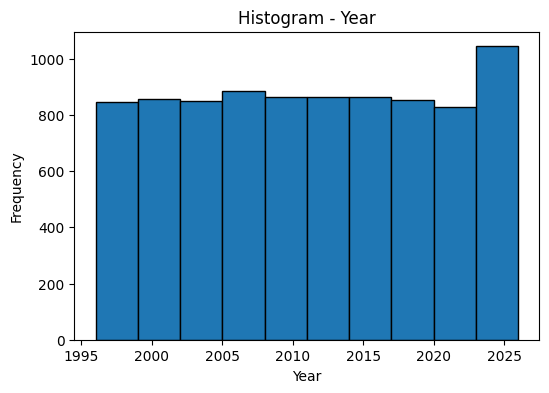

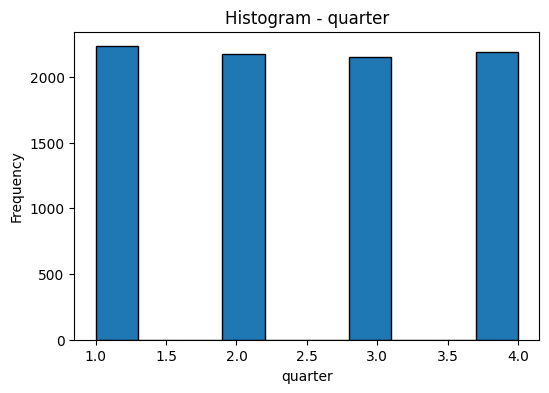

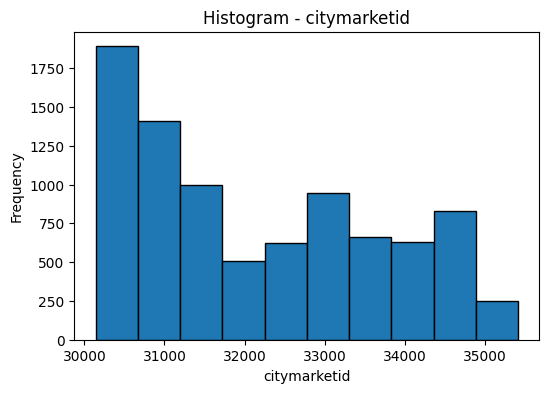

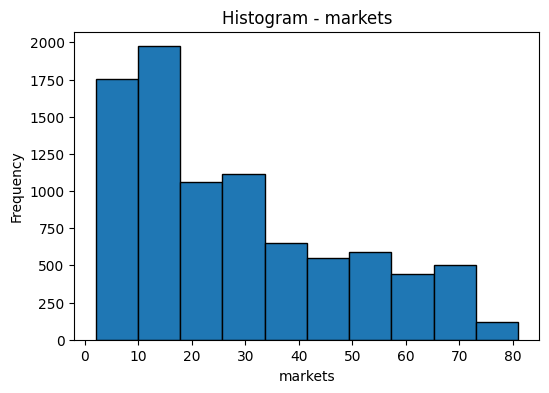

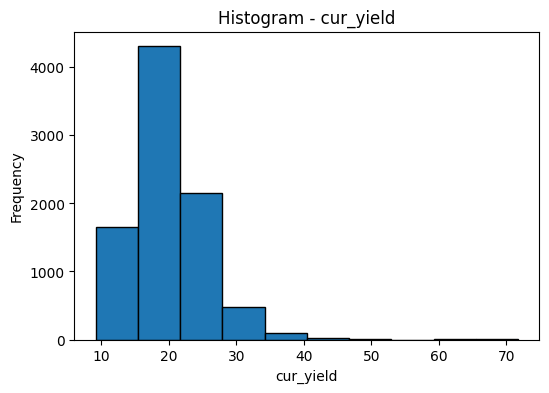

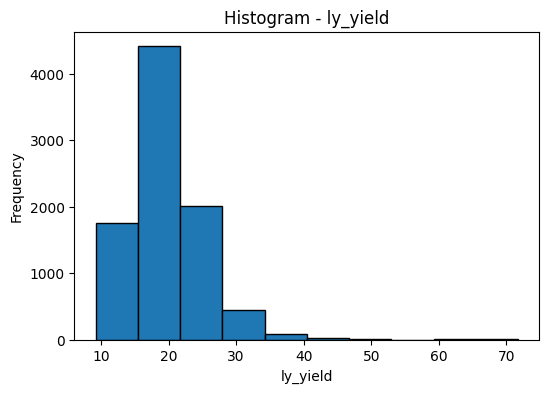

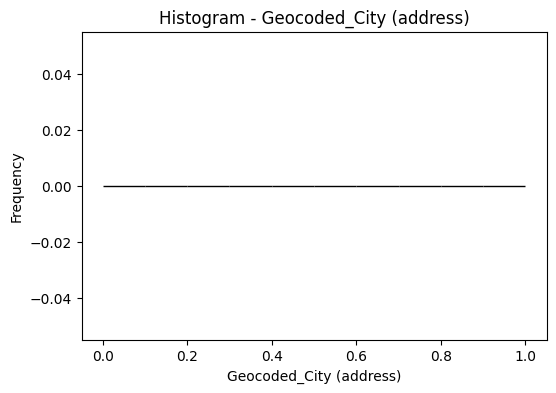

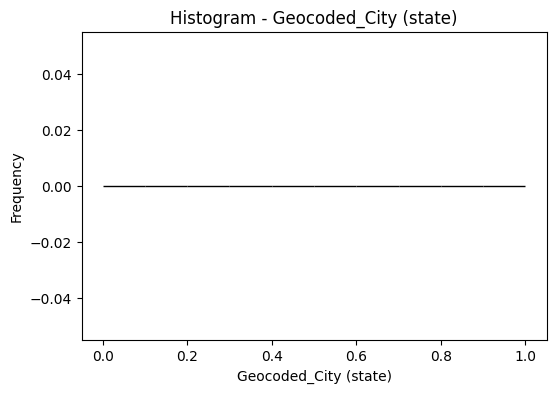

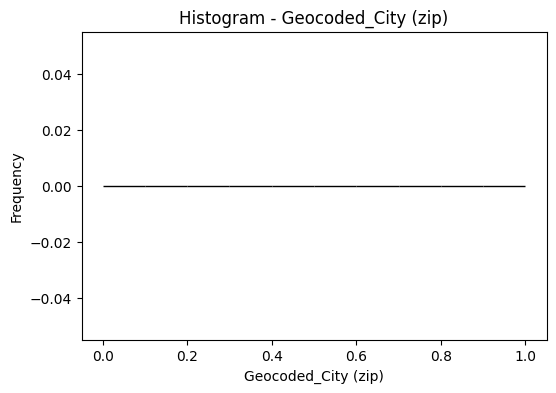

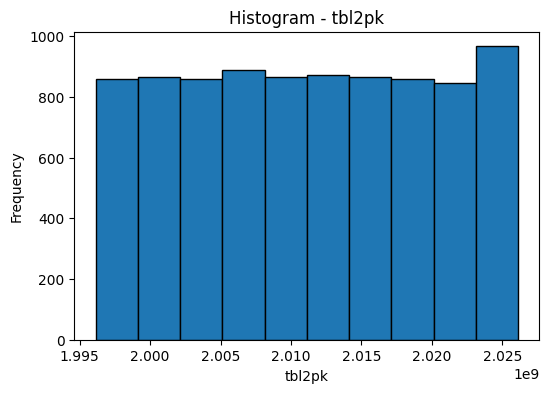

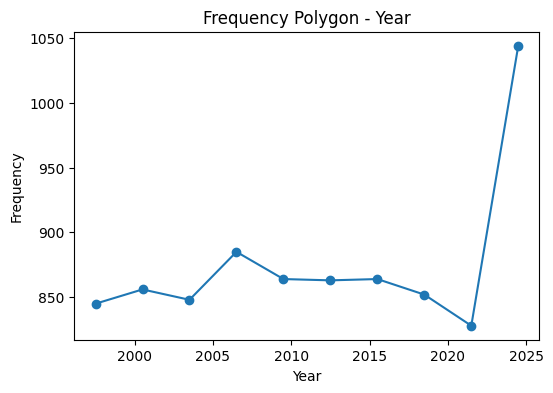

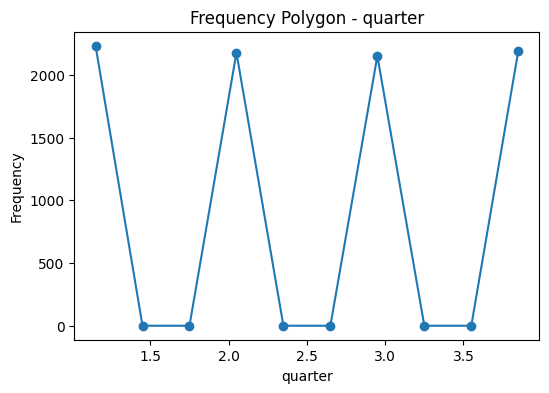

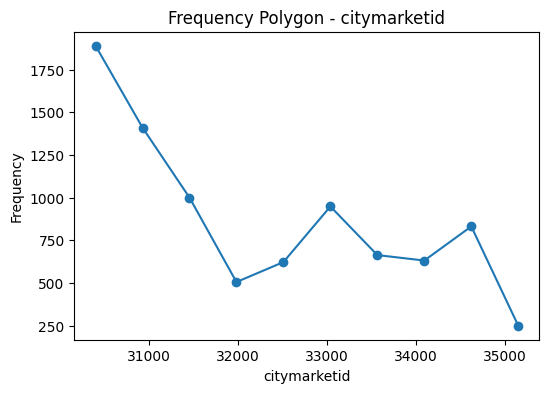

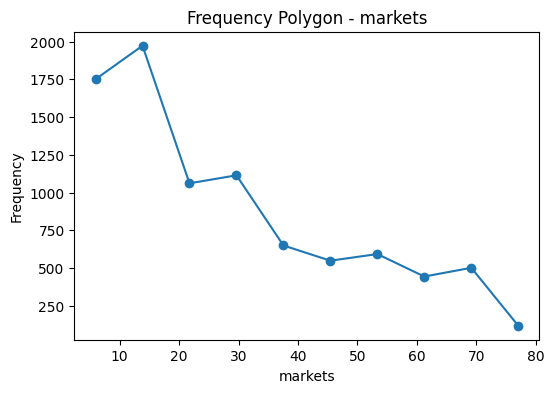

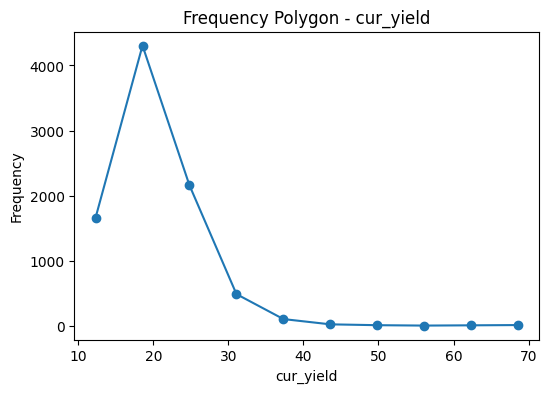

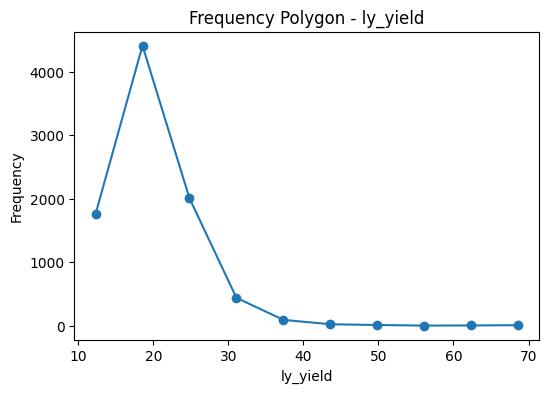

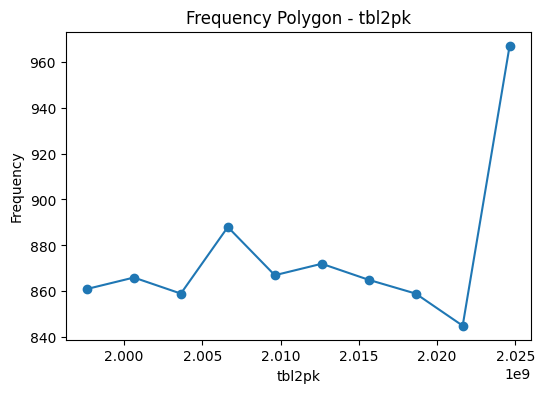

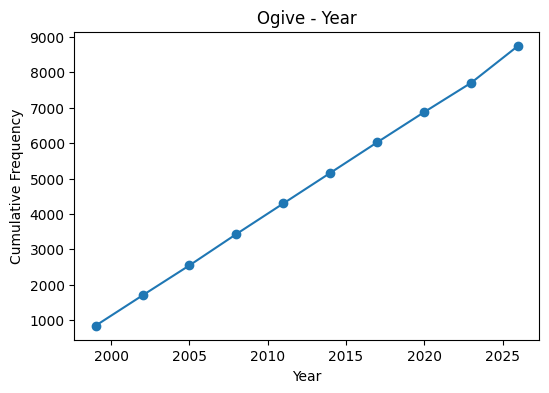

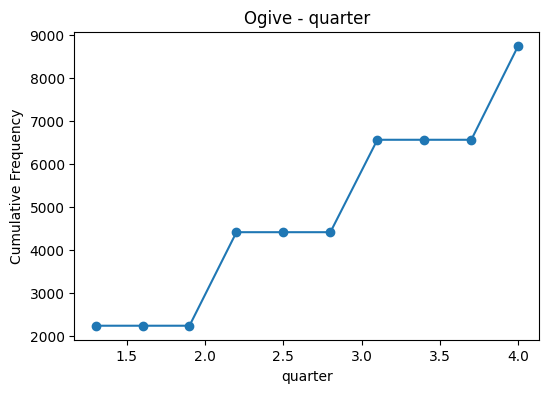

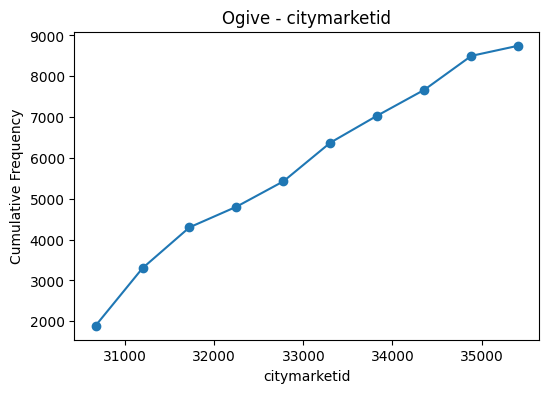

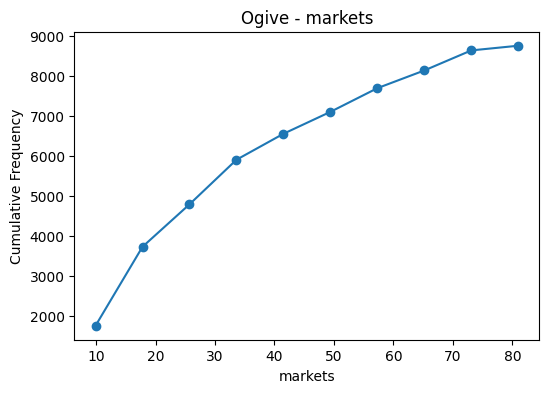

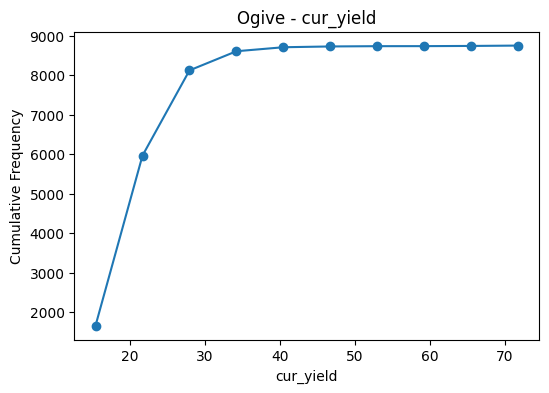

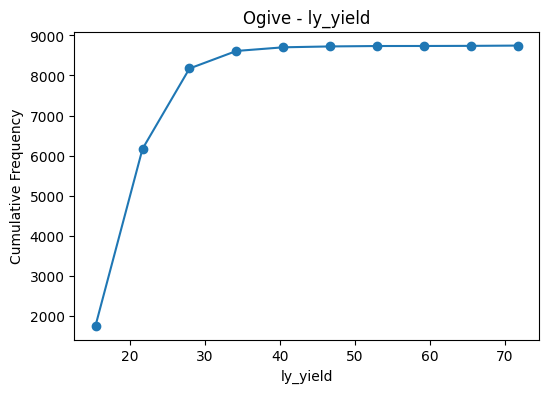

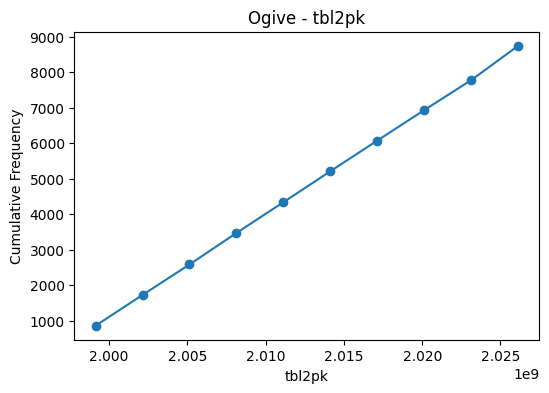

Year - Potential outliers: 0


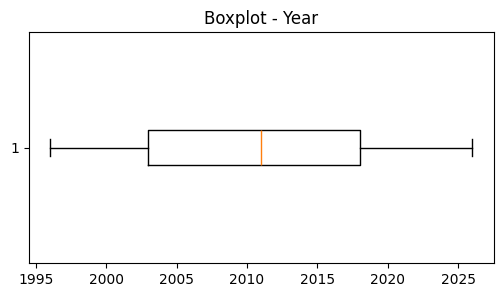

quarter - Potential outliers: 0


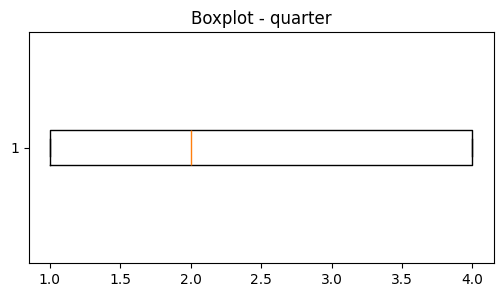

citymarketid - Potential outliers: 0


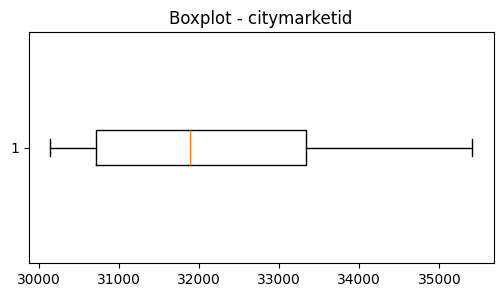

markets - Potential outliers: 0


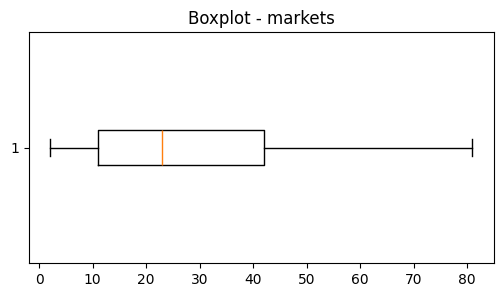

cur_yield - Potential outliers: 210


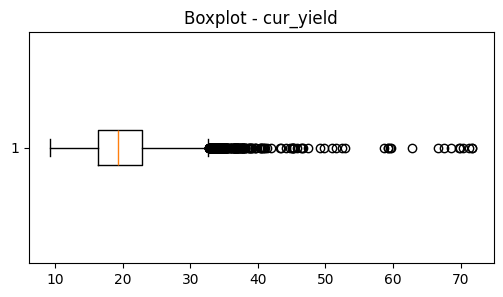

ly_yield - Potential outliers: 202


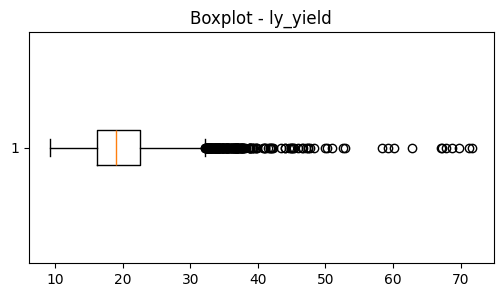

tbl2pk - Potential outliers: 0


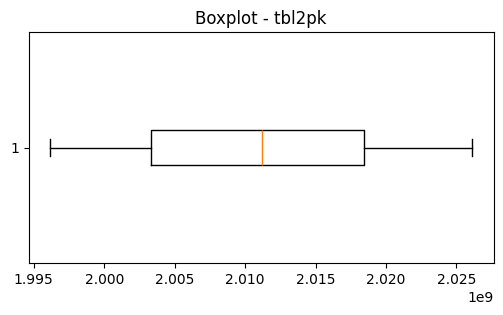

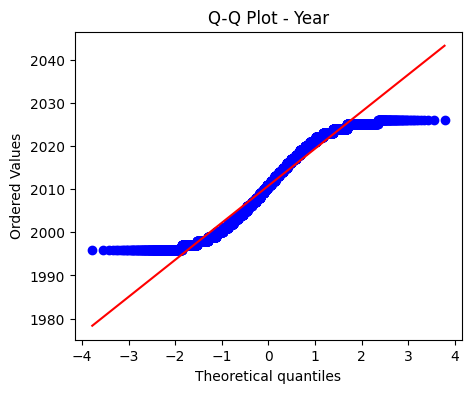

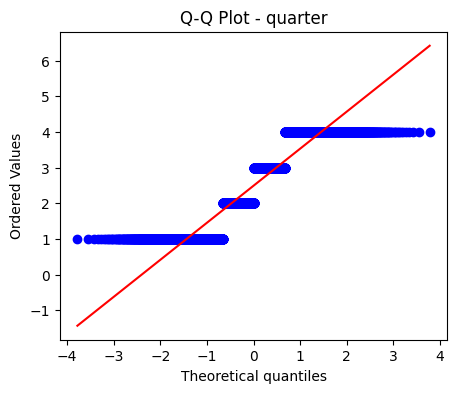

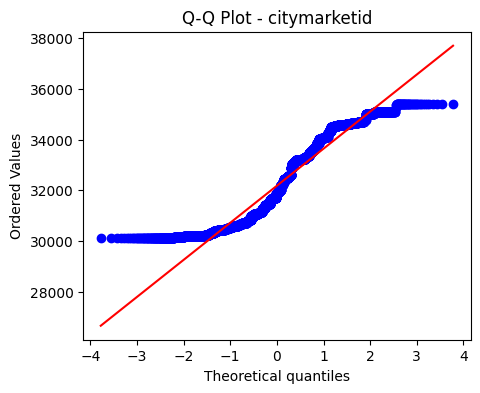

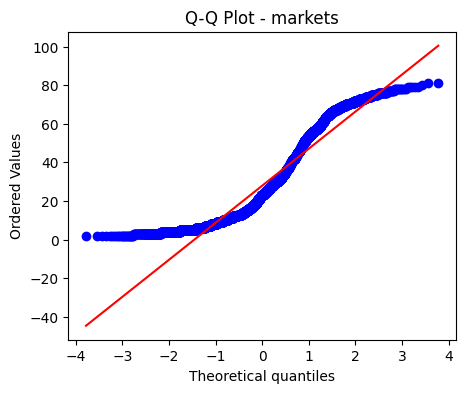

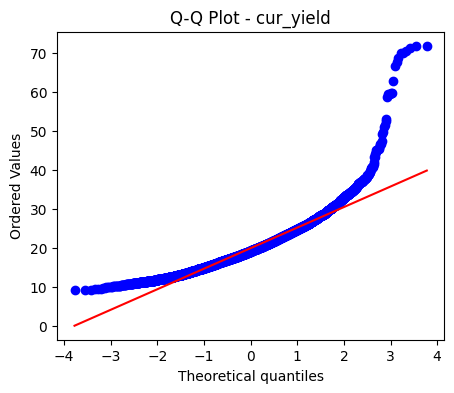

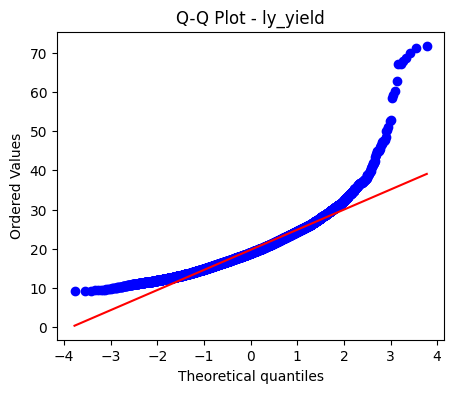

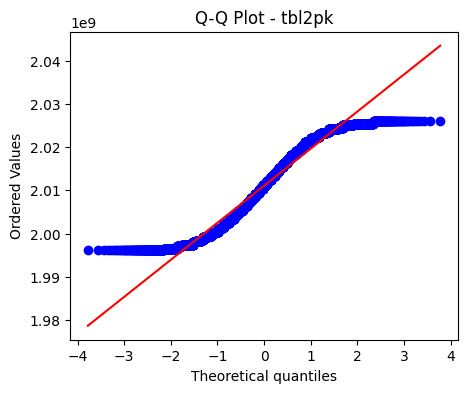

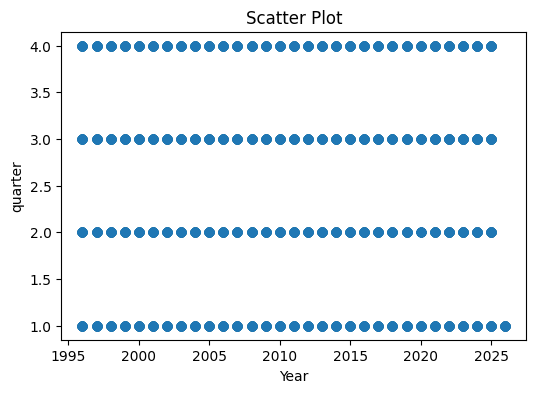

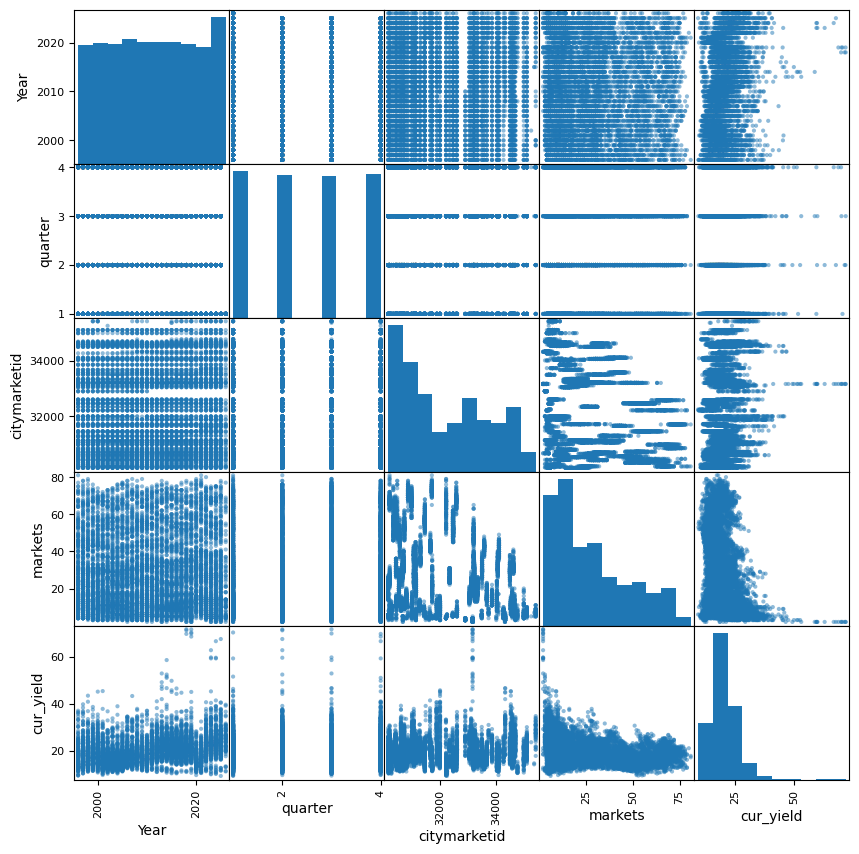

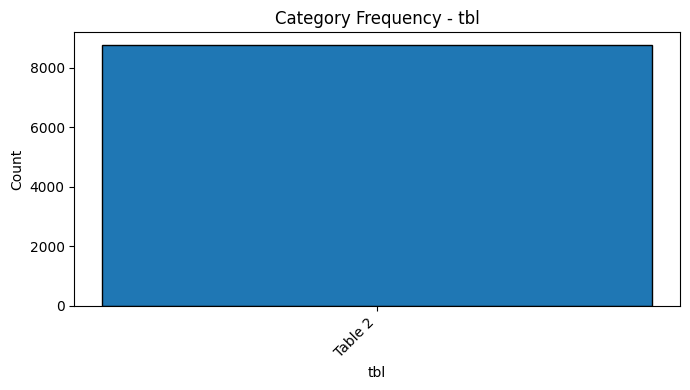

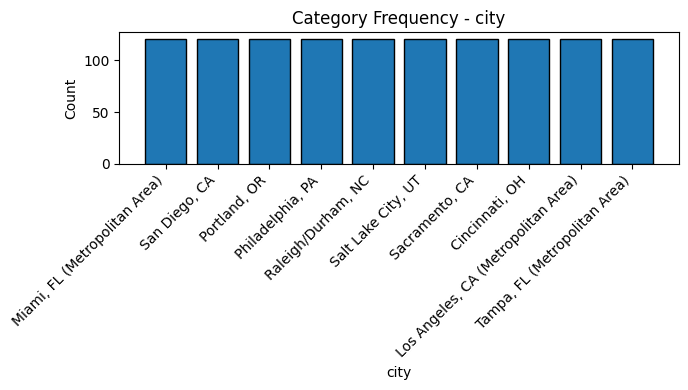

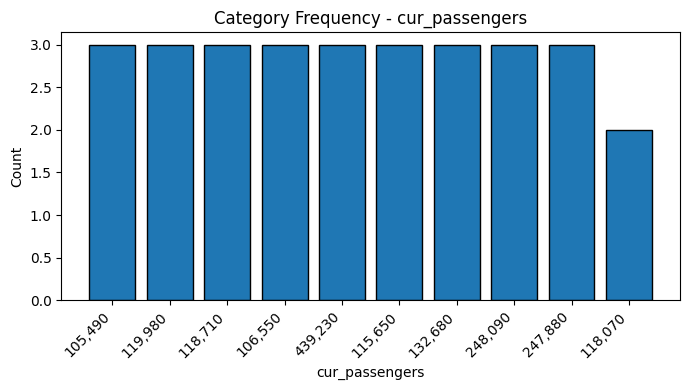

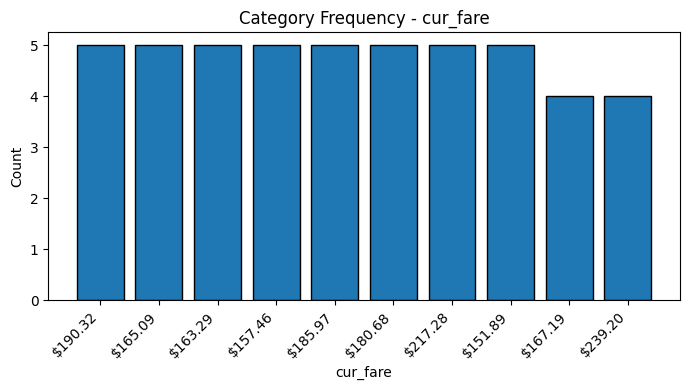

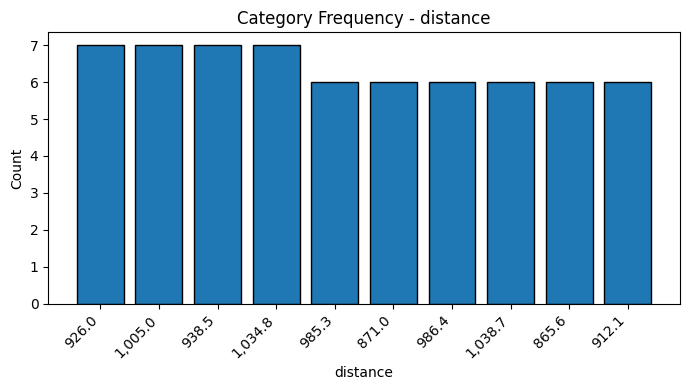

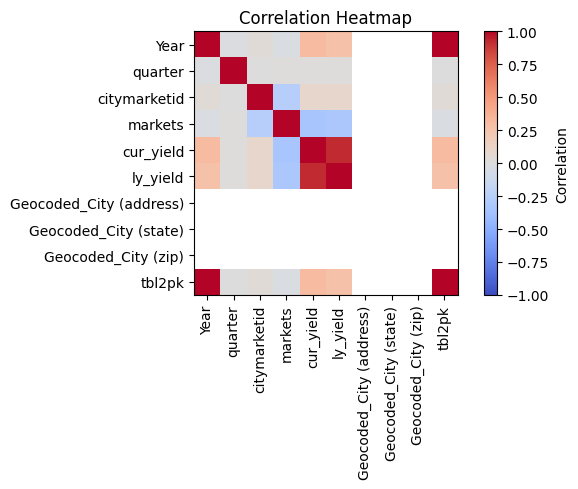

PHASE 3 VISUALIZATION COMPLETED SUCCESSFULLY!


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Upload and read dataset
from google.colab import files
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset Overview")
print(df.head())
print("Dataset Shape:", df.shape)

# Select numerical and categorical columns
num = df.select_dtypes(include=np.number)
cat = df.select_dtypes(include="object")

# 1. Histogram
for col in num.columns:
    plt.figure(figsize=(6, 4))
    plt.hist(num[col].dropna(), bins=10, edgecolor="black")
    plt.title("Histogram - " + col)
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

# 2. Frequency Polygon
for col in num.columns:
    values = num[col].dropna()
    if len(values) > 1:
        freq, bins = np.histogram(values, bins=10)
        mid = (bins[:-1] + bins[1:]) / 2
        plt.figure(figsize=(6, 4))
        plt.plot(mid, freq, marker="o")
        plt.title("Frequency Polygon - " + col)
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.show()

# 3. Cumulative Frequency Curve (Ogive)
for col in num.columns:
    values = num[col].dropna()
    if len(values) > 0:
        freq, bins = np.histogram(values, bins=10)
        plt.figure(figsize=(6, 4))
        plt.plot(bins[1:], np.cumsum(freq), marker="o")
        plt.title("Ogive - " + col)
        plt.xlabel(col)
        plt.ylabel("Cumulative Frequency")
        plt.show()

# 4. Boxplot and Outlier Detection
for col in num.columns:
    values = num[col].dropna()
    if len(values) > 0:
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1
        outliers = values[
            (values < q1 - 1.5 * iqr) |
            (values > q3 + 1.5 * iqr)
        ]
        print(col, "- Potential outliers:", len(outliers))
        plt.figure(figsize=(6, 3))
        plt.boxplot(values, vert=False)
        plt.title("Boxplot - " + col)
        plt.show()

# 5. Q-Q Plot
for col in num.columns:
    values = num[col].dropna()
    if len(values) >= 3:
        plt.figure(figsize=(5, 4))
        stats.probplot(values, dist="norm", plot=plt)
        plt.title("Q-Q Plot - " + col)
        plt.show()

# 6. Scatter Plot
if len(num.columns) >= 2:
    plt.figure(figsize=(6, 4))
    plt.scatter(num.iloc[:, 0], num.iloc[:, 1])
    plt.xlabel(num.columns[0])
    plt.ylabel(num.columns[1])
    plt.title("Scatter Plot")
    plt.show()

# 7. Pair Plot
if len(num.columns) >= 2:
    from pandas.plotting import scatter_matrix
    scatter_matrix(num.iloc[:, :5].dropna(), figsize=(10, 10))
    plt.show()

# 8. Categorical Bar Charts
for col in cat.columns[:5]:
    counts = cat[col].fillna("Missing").astype(str).value_counts().head(10)
    plt.figure(figsize=(7, 4))
    plt.bar(counts.index, counts.values, edgecolor="black")
    plt.title("Category Frequency - " + col)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# 9. Correlation Heatmap
if len(num.columns) >= 2:
    corr = num.corr()
    plt.figure(figsize=(7, 5))
    plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    plt.colorbar(label="Correlation")
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()

print("PHASE 3 VISUALIZATION COMPLETED SUCCESSFULLY!")

In [6]:

# =====================================================
# FDS MINI COMPETITION
# PHASE 4: DATA INTERPRETATION & STORYTELLING
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. UPLOAD AND LOAD DATASET

from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("=" * 50)
print("PHASE 4: DATA INTERPRETATION & STORYTELLING")
print("=" * 50)

print("\nDATASET OVERVIEW")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nFirst Five Records:")
print(df.head())

# Identify numerical and categorical columns

num = df.select_dtypes(include=np.number)
cat = df.select_dtypes(include=["object", "category", "bool"])

# 2. MEASURES OF CENTRAL TENDENCY

print("\n" + "=" * 50)
print("1. MEASURES OF CENTRAL TENDENCY")
print("=" * 50)

for col in num.columns:

    values = num[col].dropna()

    if len(values) == 0:
        continue

    print("\nColumn:", col)
    print("Mean:", round(values.mean(), 2))
    print("Median:", round(values.median(), 2))
    print("Mode:", values.mode().tolist())

    # Geometric Mean for positive values
    positive_values = values[values > 0]

    if len(positive_values) == len(values):
        print("Geometric Mean:", round(
            np.exp(np.log(values).mean()), 2
        ))
    else:
        print("Geometric Mean: Not calculated (values must be positive)")

# 3. MEASURES OF DISPERSION

print("\n" + "=" * 50)
print("2. MEASURES OF DISPERSION")
print("=" * 50)

for col in num.columns:

    values = num[col].dropna()

    if len(values) == 0:
        continue

    mean = values.mean()

    print("\nColumn:", col)
    print("Range:", round(values.max() - values.min(), 2))
    print("Variance:", round(values.var(), 2))
    print("Standard Deviation:", round(values.std(), 2))
    print("Root Mean Square:", round(np.sqrt(np.mean(values ** 2)), 2))

    if mean != 0:
        print("Coefficient of Variation (%):",
              round((values.std() / abs(mean)) * 100, 2))
    else:
        print("Coefficient of Variation: Undefined (mean is zero)")

# 4. SKEWNESS AND KURTOSIS

print("\n" + "=" * 50)
print("3. SHAPE MEASURES")
print("=" * 50)

for col in num.columns:

    values = num[col].dropna()

    if len(values) < 3:
        continue

    skewness = values.skew()
    kurtosis = values.kurt()

    print("\nColumn:", col)
    print("Skewness:", round(skewness, 2))
    print("Kurtosis:", round(kurtosis, 2))

    if skewness > 0.5:
        print("Interpretation: Positively skewed distribution")
    elif skewness < -0.5:
        print("Interpretation: Negatively skewed distribution")
    else:
        print("Interpretation: Approximately symmetric distribution")

# 5. OUTLIER ANALYSIS USING IQR

print("\n" + "=" * 50)
print("4. OUTLIER ANALYSIS")
print("=" * 50)

for col in num.columns:

    values = num[col].dropna()

    if len(values) == 0:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = values[(values < lower) | (values > upper)]

    print("\nColumn:", col)
    print("Q1:", round(q1, 2))
    print("Q3:", round(q3, 2))
    print("IQR:", round(iqr, 2))
    print("Potential Outliers:", len(outliers))

# 6. CORRELATION ANALYSIS

print("\n" + "=" * 50)
print("5. CORRELATION ANALYSIS")
print("=" * 50)

if len(num.columns) >= 2:

    corr = num.corr()

    print(corr.round(2))

    # Find strongest correlation
    pairs = []

    for i in range(len(corr.columns)):
        for j in range(i + 1, len(corr.columns)):

            value = corr.iloc[i, j]

            if pd.notna(value):
                pairs.append((
                    abs(value),
                    value,
                    corr.columns[i],
                    corr.columns[j]
                ))

    if pairs:
        pairs.sort(reverse=True)

        _, value, col1, col2 = pairs[0]

        print("\nStrongest correlation:")
        print(col1, "and", col2)
        print("Correlation coefficient:", round(value, 2))

        if value > 0.5:
            print("Interpretation: Strong positive association")
        elif value < -0.5:
            print("Interpretation: Strong negative association")
        else:
            print("Interpretation: No strong linear association detected")

        print("Note: Correlation does not prove causation.")

else:
    print("At least two numerical columns are needed.")

# 7. CATEGORICAL DATA ANALYSIS

print("\n" + "=" * 50)
print("6. CATEGORICAL DATA ANALYSIS")
print("=" * 50)

for col in cat.columns:

    print("\nColumn:", col)
    print("Unique Categories:", df[col].nunique())

    print("Most Common Values:")
    print(df[col].value_counts(dropna=False).head(5))

# 8. AUTOMATIC INSIGHTS

print("\n" + "=" * 50)
print("7. KEY INSIGHTS")
print("=" * 50)

print("Total records analysed:", len(df))

if df.isnull().sum().sum() > 0:
    print("Finding: Missing data exists and should be investigated.")
else:
    print("Finding: No missing data was detected.")

if df.duplicated().sum() > 0:
    print("Finding: Duplicate records exist and should be reviewed.")
else:
    print("Finding: No duplicate records were detected.")

for col in num.columns:

    values = num[col].dropna()

    if len(values) == 0:
        continue

    print("\n", col)

    if values.mean() > values.median():
        print("Mean exceeds median; this may indicate right skew.")
    elif values.mean() < values.median():
        print("Mean is below median; this may indicate left skew.")
    else:
        print("Mean and median are approximately equal.")

# 9. ACTIONABLE RECOMMENDATIONS

print("\n" + "=" * 50)
print("8. ACTIONABLE RECOMMENDATIONS")
print("=" * 50)

print("1. Investigate missing values before drawing conclusions.")
print("2. Check duplicate records for possible data quality issues.")
print("3. Investigate potential outliers using domain knowledge.")
print("4. Use correlation to identify relationships between variables.")
print("5. Explain findings in the context of the dataset.")
print("6. Recommend actions supported by the observed results.")
print("7. Collect additional data when causes remain uncertain.")

# 10. FINAL CONCLUSION

print("\n" + "=" * 50)
print("FINAL CONCLUSION")
print("=" * 50)

print("The dataset was analysed using statistical measures,")
print("distribution shape, outlier detection and correlation.")
print("The results can support data-driven decisions.")
print("Final recommendations should reflect the actual findings")
print("and the real-world context of the dataset.")

print("\nPHASE 4 COMPLETED SUCCESSFULLY!")

Saving export (1).csv to export (1) (2).csv
PHASE 4: DATA INTERPRETATION & STORYTELLING

DATASET OVERVIEW
Total Rows: 8749
Total Columns: 20
Missing Values: 30612
Duplicate Rows: 0

First Five Records:
       tbl  Year  quarter  citymarketid                    city  markets  \
0  Table 2  2026        1         35412           Knoxville, TN       11   
1  Table 2  2026        1         35096            Syracuse, NY        4   
2  Table 2  2026        1         34986  Sarasota/Bradenton, FL       18   
3  Table 2  2026        1         34761             Sanford, FL        6   
4  Table 2  2026        1         34685            Savannah, GA        6   

  cur_passengers cur_fare  cur_yield distance ly_passengers  ly_fare  \
0        276,827  $224.16      29.44    761.3       261,110  $211.65   
1        142,498  $207.87      21.08    986.3       145,670  $182.67   
2        706,330  $246.34      24.02  1,025.5       686,190  $212.85   
3        181,793  $122.26      12.96    943.4       1